# Tempo de implementação com e sem IA: análise

Projeto final de MCEQ (PUC-Campinas). Este notebook segue o protocolo da equipe (`protocolo.pdf` no repositório).

**Pergunta:** permitir IA altera o tempo total de implementação das issues?
**Teste planejado:** t pareado bilateral (α = 0,05) sobre a média do log do tempo por desenvolvedor. Se as diferenças não forem normais (Shapiro-Wilk), usamos o Wilcoxon pareado.

Para rodar: *Ambiente de execução → Executar tudo*.

## 1. Bibliotecas

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter
from scipy import stats

ALFA = 0.05  # definido no protocolo, antes da análise

## 2. Baixar os dados

Baixa o `data_complete.csv` direto do repositório do METR. O arquivo não fica no nosso repositório porque a fonte não declara licença.

In [2]:
URL = "https://raw.githubusercontent.com/METR/Measuring-Early-2025-AI-on-Exp-OSS-Devs/main/data_complete.csv"
ARQ_BRUTO = Path("dados/brutos/data_complete.csv")

ARQ_BRUTO.parent.mkdir(parents=True, exist_ok=True)
if not ARQ_BRUTO.exists():
    urlretrieve(URL, ARQ_BRUTO)

bruto = pd.read_csv(ARQ_BRUTO)
print("Linhas (issues):", len(bruto))
print("Desenvolvedores:", bruto["dev_id"].nunique())
bruto.head()

Linhas (issues): 246
Desenvolvedores: 16


,dev_id,issue_id,predicted_time_no_ai,predicted_time_ai_allowed,prior_task_exposure_1_to_5,external_resource_needs_1_to_3,ai_treatment,initial_implementation_time,post_review_implementation_time
0,655,1,360.0,240.0,NaN,NaN,1.0,232.0,10.0
1,655,2,60.0,30.0,NaN,NaN,1.0,36.0,0.0
2,655,3,180.0,180.0,NaN,NaN,0.0,170.0,30.0
3,655,4,300.0,240.0,NaN,NaN,1.0,420.0,20.0
4,655,5,180.0,120.0,NaN,NaN,0.0,422.0,0.0


## 3. Limpeza

- Cria o nome dos grupos (0 = Sem IA, 1 = Com IA).
- Exclui as issues sem `post_review_implementation_time`, como está no protocolo.
- Calcula o tempo total (inicial + pós-revisão) e o log desse tempo.

Os dados brutos nunca são editados: o resultado vai para `dados/limpos/`.

In [3]:
dados = bruto.copy()
dados["grupo"] = dados["ai_treatment"].map({0: "Sem IA", 1: "Com IA"})

sem_pos_revisao = dados["post_review_implementation_time"].isna()
print("Issues excluídas por falta de tempo pós-revisão:", sem_pos_revisao.sum())
print(dados.loc[sem_pos_revisao, "grupo"].value_counts().to_string())

dados = dados[~sem_pos_revisao].copy()
dados["tempo_total"] = dados["initial_implementation_time"] + dados["post_review_implementation_time"]
dados["log_tempo"] = np.log(dados["tempo_total"])

print()
print("Issues que sobraram:", len(dados))
print(dados["grupo"].value_counts().to_string())

ARQ_LIMPO = Path("dados/limpos/dados_limpos.csv")
ARQ_LIMPO.parent.mkdir(parents=True, exist_ok=True)
dados.to_csv(ARQ_LIMPO, index=False)

Issues excluídas por falta de tempo pós-revisão: 16
grupo
Com IA    9
Sem IA    7

Issues que sobraram: 230
grupo
Com IA    127
Sem IA    103


## 4. Estatística descritiva (por issue)

Tempo total em minutos, por grupo. Essa é a tabela de descritiva do artigo.

In [4]:
descritiva = (
    dados.groupby("grupo")["tempo_total"]
    .agg(n="count", media="mean", mediana="median", desvio_padrao="std", minimo="min", maximo="max")
    .loc[["Sem IA", "Com IA"]]
    .round(1)
)
descritiva

,n,media,mediana,desvio_padrao,minimo,maximo
grupo,,,,,,
Sem IA,103,97.2,75.0,89.2,6.0,500.0
Com IA,127,134.3,90.0,132.3,7.0,680.0


## 5. Pareamento por desenvolvedor

Cada desenvolvedor fez tarefas nos dois grupos. Para cada um, calculamos a média do log do tempo **sem IA** e **com IA**. Isso dá 16 pares, e a diferença de cada par (com IA − sem IA) é o que o teste analisa.

Diferença positiva = o desenvolvedor demorou mais com IA.

In [5]:
por_dev = dados.groupby(["dev_id", "grupo"])["log_tempo"].mean().unstack()[["Sem IA", "Com IA"]]
por_dev["diferenca"] = por_dev["Com IA"] - por_dev["Sem IA"]

n_pares = len(por_dev)
print("Pares (desenvolvedores):", n_pares)
por_dev.round(3)

Pares (desenvolvedores): 16


grupo,Sem IA,Com IA,diferenca
dev_id,,,
26,4.124,4.660,0.536
90,3.454,4.056,0.602
105,4.242,4.292,0.050
115,4.249,5.247,0.998
143,4.062,4.207,0.145
229,5.247,4.331,-0.916
251,4.245,4.528,0.283
282,3.718,4.585,0.867
559,4.521,4.939,0.418


## 6. Figura

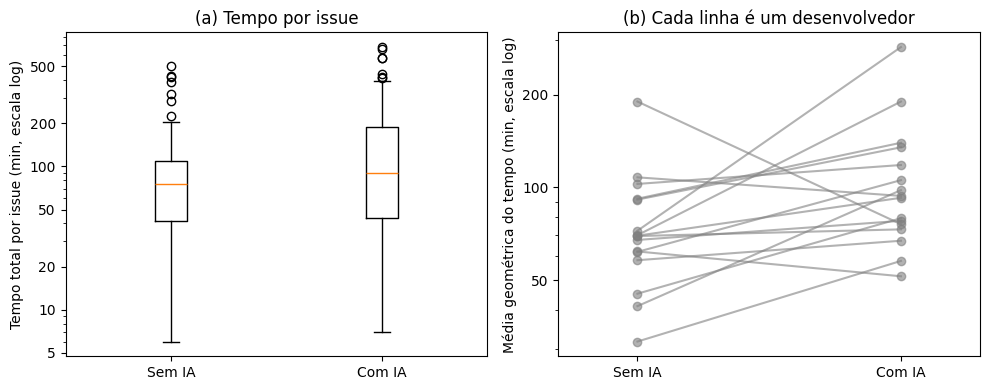

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# (a) tempo de cada issue, por grupo
ordem = ["Sem IA", "Com IA"]
ax1.boxplot([dados.loc[dados["grupo"] == g, "tempo_total"] for g in ordem], tick_labels=ordem)
ax1.set_yscale("log")
ax1.set_ylabel("Tempo total por issue (min, escala log)")
ax1.set_title("(a) Tempo por issue")

# (b) cada linha é um desenvolvedor
media_geo = np.exp(por_dev[["Sem IA", "Com IA"]])
for _, linha in media_geo.iterrows():
    ax2.plot([0, 1], linha.values, marker="o", color="gray", alpha=0.6)
ax2.set_xticks([0, 1], ordem)
ax2.set_xlim(-0.3, 1.3)
ax2.set_yscale("log")
ax2.set_ylabel("Média geométrica do tempo (min, escala log)")
ax2.set_title("(b) Cada linha é um desenvolvedor")

# eixos com números normais (10, 20, 50, 100...) em vez de notação científica
for ax in (ax1, ax2):
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())

fig.tight_layout()
Path("figuras").mkdir(exist_ok=True)
fig.savefig("figuras/figura1.png", dpi=200)
plt.show()

## 7. Teste de normalidade das diferenças (Shapiro-Wilk)

Decide qual teste usar, como está no protocolo:
- p ≥ 0,05 → as diferenças podem ser consideradas normais → **t pareado**
- p < 0,05 → não são normais → **Wilcoxon pareado**

In [7]:
shapiro = stats.shapiro(por_dev["diferenca"])
print(f"Shapiro-Wilk: W = {shapiro.statistic:.3f}, p = {shapiro.pvalue:.3f}")

usar_t = shapiro.pvalue >= ALFA
print("Teste a usar:", "t pareado" if usar_t else "Wilcoxon pareado")

Shapiro-Wilk: W = 0.971, p = 0.854
Teste a usar: t pareado


## 8. Teste de hipótese, tamanho de efeito e intervalo de confiança

- **p-valor:** se for menor que 0,05, rejeitamos H0 (o tempo é diferente com IA).
- **d de Cohen (pareado):** tamanho da diferença em desvios-padrão. Referência comum: 0,2 pequeno, 0,5 médio, 0,8 grande.
- **IC 95%:** faixa de valores plausíveis para a diferença.
- **Razão dos tempos:** `exp(diferença)`. Ex.: 1,20 = com IA levou 20% mais tempo; 0,80 = levou 20% menos.

In [8]:
dif = por_dev["diferenca"]
media_dif = dif.mean()
dp_dif = dif.std(ddof=1)
gl = n_pares - 1

# intervalo de confiança de 95% da diferença média (em log)
t_crit = stats.t.ppf(1 - ALFA / 2, gl)
ic_baixo = media_dif - t_crit * dp_dif / np.sqrt(n_pares)
ic_alto = media_dif + t_crit * dp_dif / np.sqrt(n_pares)

if usar_t:
    teste = stats.ttest_rel(por_dev["Com IA"], por_dev["Sem IA"])
    nome_teste = "t pareado"
    estatistica = f"t({gl}) = {teste.statistic:.3f}"
    p_valor = teste.pvalue
    efeito = f"d de Cohen (pareado) = {media_dif / dp_dif:.3f}"
else:
    teste = stats.wilcoxon(dif)
    nome_teste = "Wilcoxon pareado"
    estatistica = f"W = {teste.statistic:.1f}"
    p_valor = teste.pvalue
    # correlação bisserial de postos
    nao_zero = dif[dif != 0]
    postos = stats.rankdata(nao_zero.abs())
    r = (postos[nao_zero > 0].sum() - postos[nao_zero < 0].sum()) / postos.sum()
    efeito = f"r bisserial de postos = {r:.3f}"

razao = np.exp(media_dif)
razao_baixo, razao_alto = np.exp(ic_baixo), np.exp(ic_alto)

print("Teste:", nome_teste)
print(estatistica)
print(f"p-valor = {p_valor:.4f}")
print("Decisão:", "rejeita H0" if p_valor < ALFA else "não rejeita H0", f"(α = {ALFA})")
print(efeito)
print(f"Diferença média em log = {media_dif:.3f} (IC 95%: {ic_baixo:.3f} a {ic_alto:.3f})")
print(f"Razão dos tempos (com IA / sem IA) = {razao:.2f} (IC 95%: {razao_baixo:.2f} a {razao_alto:.2f})")
print(f"Ou seja: com IA, o tempo foi {(razao - 1) * 100:+.0f}% em relação a sem IA "
      f"(IC 95%: {(razao_baixo - 1) * 100:+.0f}% a {(razao_alto - 1) * 100:+.0f}%)")

Teste: t pareado
t(15) = 2.482
p-valor = 0.0254
Decisão: rejeita H0 (α = 0.05)
d de Cohen (pareado) = 0.620
Diferença média em log = 0.329 (IC 95%: 0.047 a 0.612)
Razão dos tempos (com IA / sem IA) = 1.39 (IC 95%: 1.05 a 1.84)
Ou seja: com IA, o tempo foi +39% em relação a sem IA (IC 95%: +5% a +84%)


## 9. Versões das bibliotecas

Para o `requirements.txt` e para o artigo.

In [9]:
import sys, scipy, matplotlib
print("Python", sys.version.split()[0])
print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18
pandas 2.2.3 | numpy 2.4.6 | scipy 1.16.3 | matplotlib 3.10.0
